# 01 - Exploratory Data Analysis

## Purpose

This Notebook should cover the **Data Understanding** phase of the CRISP-DM methodology, right now applied to the Home Credit Default Risk dataset. Its goal is not to explore for its own sake but rather to surface the specific facts about the data that will drive and help us with concrete modeling decisions in later notebooks.

## Questions this notebook answers

1. What is the target variable and how imbalanced is it? 

2. What is the feature inventory, lets say numeric, categorial, dates encoded as integer and what are their basic distributions? 

3. Where is data missing, and if that missingness is informative(i.e. does missingness itself help on the default prediction?)

4. Which sentinel values encode "not applicable" as numbers and must be cleaned?

5. Do the known and assumable strong predictors (age, credit to income, etc) show the expected single and one directional relationship with default rate?

6. Which features are highly correlated and will need attention during feature selection (portraying the same effects through multicollinearity)?

7. Which categorical variables have rare levels that require grouping?

## Scope 

- In this notebook only the 'application_train.csv' will be analyzed. The bureau and previous-application tables are going to be deferred to the Notebook 02, where they will be aggregated to the "SK_ID_CURR" junction during feature engineering.

- All findings that carry into modeling decisions are collected in the final section of the document as "Decisions carried forward",

## Methodology

CRISP-DM Data Understanding tasks: Collect the initial data, describe the data, explore the data and verify data quality. Each analytical section will pair code with a short written observation stating what was seen, what it means, and what decision it implies. 

## Data

- Source: Home Credit Default Risk, Kaggle competition (2018).
- File: 'data/raw/application_train.csv' (~166 MB, 307,511 rows).
---

## Key findings

- **Target imbalance (~8.1% default).** Accuracy is disqualified as an absolute measure, 
  model discrimination is going to be judged with Gini, KS, and ROC-AUC. The natural class
  distribution is preserved with these methods, which also protects the
  probability calibration required for IFRS 9.

- **Informative missingness.** Missingness is not always random, the absence of an
  external score (`EXT_SOURCE_1`) predicts higher default. Missingness will be
  preserved as signal via indicator flags for the logistic scorecard, the
  LightGBM challenger handles NaN natively.

- **Sentinel and anomalous values.** `DAYS_EMPLOYED` carries a 365243 sentinel
  (55,374 rows, ~18% presence), `AMT_INCOME_TOTAL` has an implausible 117M outlier,
  `CODE_GENDER` contains 4 invalid `XNA`  and `ORGANIZATION_TYPE` contains 55,374 `XNA` rows. The employment sentinel was
  flagged and nulled, the income outlier and XNA rows are deferred to the data
  preparation.

- **Feature relationships vary in shape.** Across deciles, `EXT_SOURCE_2` is
  cleanly monotonic (~6× spread), age is monotonic with a mid-range plateau,
  and the credit-to-income ratio is non-monotonic (with a hump). This variation
  justifies Weight-of-Evidence bin by bin encoding and implies a per feature
  binning strategy (monotonic vs. peak and unconstrained).

- **Modest single-feature signal.** The strongest correlations with the target
  are only ~0.15–0.18 in absolute values, confirming that no single predictor
  suffices and a multi-feature model is required.

- **Heavy multicollinearity.** 113 feature pairs exceed 0.8 absolute correlation
  (housing `_AVG`/`_MODE`/`_MEDI` triplets, engineered duplicates, and the
  substantive `AMT_CREDIT`/`AMT_GOODS_PRICE` pair). Redundant features will be
  pruned during selection to stabilize the scorecard coefficients, what is relevant to
  the logistic scorecard, not for the tree-based model. 

These findings define the data-preparation and feature-engineering tasks for
notebook 02.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from pathlib import Path

# Setting the display to show all columns in a wider console output before wrapping.

pd.set_option("display.max.columns", None)
pd.set_option("display.width", 200)

# The notebook lives in the 'root'/notebooks/, so the project root is one level up. 

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

raw = ROOT / "data" / "raw"
processed = ROOT / "data" / "processed"
processed.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("CSV exists?", (raw / "application_train.csv").exists())

Project root: c:\dev\credit-risk-pd-model
CSV exists? True


In [2]:
# Convert the main training file to Parquet once, for faster reloads. 
# CSV parsing is slow, considering that every value is re-parsed from text for each load.
# Parquet stores typed, compressed columns and loads roughly 5-10x faster.

csv_path = raw / "application_train.csv"
parquet_path = processed / "application_train.parquet"

if not parquet_path.exists():
    df_csv = pd.read_csv(csv_path)
    df_csv.to_parquet(parquet_path, engine="pyarrow", index=False)
    print(f"Converted to Parquet: {parquet_path}")
else:
    print(f"Parquet file already exists: {parquet_path}")

Parquet file already exists: c:\dev\credit-risk-pd-model\data\processed\application_train.parquet


In [3]:
df = pd.read_parquet(parquet_path)

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns") 
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
df.head()

Shape: 307511 rows x 122 columns
Memory: 341.0 MB


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

**What I see:** There are 307,511 applications, 122 columns. The **SK_ID_CURR column** is a unique identifier of the dataset. **TARGET** is the label column, where 1 indicates a defaulted loan and 0 indicates a non-defaulted loan. Many columns are float types with visible NaNs already in the first rows.

**Interpretation:** This is a wide dataset with substantial missingness. The 122 columns will need triage into either numeric, categorical and identifier clusters. 

**Decision:** Next step is to quantify the target balances and build a column type inventory for each feature of the dataset. 

In [4]:
#Target balances 

target_counts = df["TARGET"].value_counts()
target_rate = df["TARGET"].value_counts(normalize=True)

print("Counts:")
print(target_counts)
print("\nProportions:")
print(target_rate)



Counts:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Proportions:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


**What I see:** The target is imbalanced. Roughly 8.1% of applications are labelled as payment difficulty-cases, with 'TARGET = 1', against 91.9% non-difficulty cases ('Target = 0').

**Interpretation:** This imbalance disqualifies accuracy as an evaluation metric. A naive model that predicts "no default" for every applicant would be ~92% accurate while identifiying none of the actual defaults, that means, it will be useless to a lender. The model performance must therefore be judged with ranking and discrimination metrics (Gini, KS, ROC-AUC), statistical metrics used to evaluate and measure how well a model separates positive and negative outcomes. Here a no skill baseline corresponds to a AUC of 0.5, a Gini of 0. The imbalance is moderate, not extreme, so resampling (using SMOTE for example) is unecessary and would be avoided regardless, since it distorts the probability calibration required for PD (Probability Default) and ECL (Expected Credit Loss). 

**Decision:** Adopt Gini/KS/AUC as primary metrics and preserve the natural class distribution. Next, as already mentioned, build a column type inventory (numeric / categorical / identifier / data-encoded).

In [5]:
# Column-type inventory 
dtype_summary = df.dtypes.value_counts()

print("Column counts by dtype:")
print(dtype_summary)

# Separate the columns into groups

numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=["number"]).columns.tolist()

print(f"\nNumeric columns: {len(numeric_cols)}")
print(f"Categorical (string) columns: {len(categorical_cols)}")

Column counts by dtype:
float64    65
int64      41
str        16
Name: count, dtype: int64

Numeric columns: 106
Categorical (string) columns: 16


**What I see:** Pandas reports 106 numeric columns and 16 categorical (string) columns.

**Interpretation:** The pandas dtype is not the same as the semantic type. Several columns stored as numeric are not continuous features:
- `SK_ID_CURR` is an identifier, not a predictor, and must be excluded from modelling.
- `TARGET` is the label, not a feature.
- `DAYS_*` columns are dates encoded as negative integers (days before application).
- `FLAG_*` columns are binary 0/1 indicators, effectively categorical despite being stored as int.

The raw dtype split is therefore only a starting point, the true feature inventory requires manual reclassification.

**Decision:** Treat the dtype split as provisional. During feature engineering, explicitly separate identifiers, the label, binary flags, and date-encoded integers from genuine continuous features. Next in this EDA: quantify missingness and test whether it is informative.

## 3. Missingness analysis

Missing data is quantified per column, then examined for structure and predictive signal. In credit data, missingness is frequently informative rather than random. A value may be absent for a structural reason (e.g. no car so no information about the car's age) or a behavioral one (e.g. no external credit score for a applicant with little or no credit history). Where missingness itself predicts defaul, it must be preserved as a feature rather than silently imputed. 

In [6]:
# Missingness per column: count and percentage, sorted high to low.

missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df) * 100).round(2)

missing_summary = (
    pd.DataFrame({"missing_count": missing_count, "missing_pct": missing_pct})
    .query("missing_count > 0")
    .sort_values("missing_pct", ascending=False)
)

print(f"Columns with any missing values: {len(missing_summary)} of {df.shape[1]}")
print(f"Columns with > 50% missing: {(missing_summary['missing_pct'] > 50).sum()}")
missing_summary.head(25)

Columns with any missing values: 67 of 122
Columns with > 50% missing: 41


,missing_count,missing_pct
COMMONAREA_MEDI,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_AVG,214865,69.87
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_AVG,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_MODE,210199,68.35


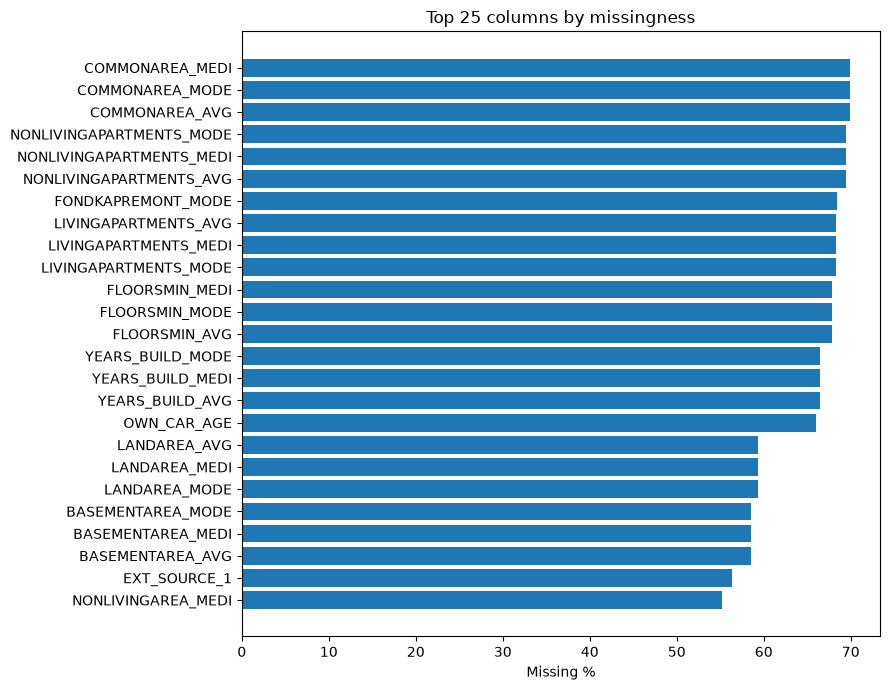

In [7]:
top_missing = missing_summary.head(25)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_missing.index, top_missing["missing_pct"])
ax.invert_yaxis()
ax.set_xlabel("Missing %")
ax.set_title("Top 25 columns by missingness")
plt.tight_layout()
plt.show()

In [8]:
# Test for wheter missingness predicts default, for a few high-missing columns. 
overall_rate = df["TARGET"].mean()
print(f"Overall default rate: {overall_rate:.4f}\n")

cols_to_test = ["EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE"]

for col in cols_to_test:
    is_missing = df[col].isnull()
    rate_missing = df.loc[is_missing, "TARGET"].mean()
    rate_present = df.loc[~is_missing, "TARGET"].mean()      # ~ not -
    print(f"{col}")
    print(f"  missing ({is_missing.mean():.1%} of rows): default rate {rate_missing:.4f}")
    print(f"  present ({(~is_missing).mean():.1%} of rows): default rate {rate_present:.4f}")
    print(f"  difference: {rate_missing - rate_present:+.4f}\n")

Overall default rate: 0.0807

EXT_SOURCE_1
  missing (56.4% of rows): default rate 0.0852
  present (43.6% of rows): default rate 0.0750
  difference: +0.0102

EXT_SOURCE_3
  missing (19.8% of rows): default rate 0.0931
  present (80.2% of rows): default rate 0.0777
  difference: +0.0155

OWN_CAR_AGE
  missing (66.0% of rows): default rate 0.0850
  present (34.0% of rows): default rate 0.0724
  difference: +0.0126



**What I see:** 67 of 122 columns contain missing values. They fall into two clusters: a large block of housing/building columns (`COMMONAREA_*`, `NONLIVINGAPARTMENTS_*`, etc.) missing at 50–70%, and behavioral columns such as the external scores (`EXT_SOURCE_1` ~56% missing, `EXT_SOURCE_3` ~19%). The housing columns share near identical missingness rates, suggesting they are absent together for a common structural reason.

**Interpretation:** Missingness here is not random. For all three tested columns, the default rate differs between the missing and present groups by at least ~1 percentage point against an 8% base rate. For `EXT_SOURCE_1` the gap is larger, consistent with the credit-risk interpretation that a missing external score signals a thin credit file. Two mechanisms are visible: structural missingness (housing data simply not collected) and behavioral missingness (no external score available). In both cases the absence itself is informative.

**Decision:** Preserve missingness as signal rather than imputing it away blindly. This creates a modeling fork carried into notebooks 02–03: the logistic-regression scorecard cannot accept NaNs and will require explicit handling (imputation plus a binary missingness indicator flag), whereas the LightGBM challenger handles NaNs natively and can be given the raw pattern. Group sizes to be reported alongside rates in a later pass.

## 4. Sentinel values and impossible entries

Some columns encode "not applicable" or "unknown" as real-looking numbers rather than leaving them blank. These sentinel values masquerade as valid data and distort any statistic or model that consumes them. They are found by inspecting each numeric column's range for physically impossible minima or maxima, then cross-checking against the data dictionary. Identified sentinels are converted to Nan so they are handled consistently with the missingness analysed above. 

In [9]:
# Inspect the range of numeric columns: impossible min/max values reveal sentinels 

desc = df.describe().T[["min", "max", "mean"]]

# Sort by max to surface suspiciously large values at the top. 

desc.sort_values("max", ascending=False).head(15)

,min,max,mean
AMT_INCOME_TOTAL,25650.0,117000000.0,168797.919297
AMT_CREDIT,45000.0,4050000.0,599025.999706
AMT_GOODS_PRICE,40500.0,4050000.0,538396.207429
SK_ID_CURR,100002.0,456255.0,278180.518577
DAYS_EMPLOYED,-17912.0,365243.0,63815.045904
AMT_ANNUITY,1615.5,258025.5,27108.573909
OBS_30_CNT_SOCIAL_CIRCLE,0.0,348.0,1.422245
OBS_60_CNT_SOCIAL_CIRCLE,0.0,344.0,1.405292
AMT_REQ_CREDIT_BUREAU_QRT,0.0,261.0,0.265474
OWN_CAR_AGE,0.0,91.0,12.061091


In [10]:
# Profile categorical columns - look for placeholder/invalid category codes.

categorical_cols = df.select_dtypes(exclude="number").columns

for col in categorical_cols:
    vals = df[col].unique()
    #Flag suspicious placeholders codes commonly used for "unknown"
    suspicious = [v for v in vals if str(v).upper() in ("XNA", "XAP", "UNKNOWN", "N/A", "")]
    if suspicious:
        print(f"{col}: suspicious codes {suspicious}")
        print(df[col].value_counts().to_string())
        print()


CODE_GENDER: suspicious codes ['XNA']
CODE_GENDER
F      202448
M      105059
XNA         4

NAME_FAMILY_STATUS: suspicious codes ['Unknown']
NAME_FAMILY_STATUS
Married                 196432
Single / not married     45444
Civil marriage           29775
Separated                19770
Widow                    16088
Unknown                      2

ORGANIZATION_TYPE: suspicious codes ['XNA']
ORGANIZATION_TYPE
Business Entity Type 3    67992
XNA                       55374
Self-employed             38412
Other                     16683
Medicine                  11193
Business Entity Type 2    10553
Government                10404
School                     8893
Trade: type 7              7831
Kindergarten               6880
Construction               6721
Business Entity Type 1     5984
Transport: type 4          5398
Trade: type 3              3492
Industry: type 9           3368
Industry: type 3           3278
Security                   3247
Housing                    2958
Industry: type

In [11]:
# How many rows carry the 365243 sentinel, and how do they differ?

sentinel = 365243
n_sentinel = (df["DAYS_EMPLOYED"] == sentinel).sum()
print(f"Rows with DAYS_EMPLOYED == {sentinel}: {n_sentinel:,} ({n_sentinel/len(df):.1%})")

# Does the sentinel group differ in default rate? (informative, like the missingness)
rate_sentinel = df.loc[df["DAYS_EMPLOYED"] == sentinel, "TARGET"].mean()
rate_normal = df.loc[df["DAYS_EMPLOYED"] != sentinel, "TARGET"].mean()
print(f"Default rate - sentinel group: {rate_sentinel:.4f}")
print(f"Default rate - normal group: {rate_normal:.4f}")

Rows with DAYS_EMPLOYED == 365243: 55,374 (18.0%)
Default rate - sentinel group: 0.0540
Default rate - normal group: 0.0866


In [12]:
# Income: look at the extreme upper tail.

print("AMT_INCOME_TOTAL - top 5 values:")
print(df["AMT_INCOME_TOTAL"].sort_values(ascending=False).head(5).to_string())
print(f"\n99.9th percentile {df['AMT_INCOME_TOTAL'].quantile(0.999):,.0f}")

AMT_INCOME_TOTAL - top 5 values:
12840     117000000.0
203693     18000090.0
246858     13500000.0
77768       9000000.0
131127      6750000.0

99.9th percentile 900,000


In [13]:
# Treatment: preserve the sentinel as a flag, then null the poisoning value.
# Flag derived from isnull() after replacement — verified equivalent to the
# 365243 sentinel (0 natural NaN in the original column), so this is re-run safe.

df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)
df["DAYS_EMPLOYED_ANOMALY"] = df["DAYS_EMPLOYED"].isnull().astype(int)

print("After replacement:")
print(f"  DAYS_EMPLOYED max: {df['DAYS_EMPLOYED'].max():,.0f}")
print(f"  DAYS_EMPLOYED NaN count: {df['DAYS_EMPLOYED'].isnull().sum():,}")
print(f"  Anomaly flag sum:  {df['DAYS_EMPLOYED_ANOMALY'].sum():,}")

After replacement:
  DAYS_EMPLOYED max: 0
  DAYS_EMPLOYED NaN count: 55,374
  Anomaly flag sum:  55,374


**What I see:** The numeric scan flags two anomalies. First, the `AMT_INCOME_TOTAL`
has an extreme right tail: the top value is 117,000,000 against a 99.9th
percentile of ~900,000, what represents roughly 130× the tail threshold and 6× the
next-highest value. Second, `DAYS_EMPLOYED` has an impossible maximum of 365,243
(~1,000 years), a sentinel present in 55,374 rows (~18%). The categorical
scan flags placeholder codes in three columns: `CODE_GENDER` (XNA, 4 rows),
`NAME_FAMILY_STATUS` (Unknown, 2 rows), and `ORGANIZATION_TYPE` (XNA, 55,374
rows). Notably, the `ORGANIZATION_TYPE` XNA count exactly matches the `DAYS_EMPLOYED` sentinel count, the same unemployed/pensioner population, who have neither an employer nor an employment duration.

**Interpretation:** The `DAYS_EMPLOYED` sentinel encodes "not currently
employed" (pensioners, unemployed) and is informative as this group defaults
at a *lower* rate than average, consistent with the informative-missingness
pattern seen earlier. The 117M income is almost certainly a data-entry
error rather than a genuine outlier, the other large incomes (18M, 13.5M)
are extreme but plausible. Neither of the project's chosen models requires outlier
clipping: WoE binning places all high incomes in a common top bin, and
tree-based LightGBM splits on rank rather than magnitude.

**Decision:** `DAYS_EMPLOYED` sentinel converted to NaN with an
`DAYS_EMPLOYED_ANOMALY` flag preserving the signal (applied and verified).
The 117M income row, the 4 `CODE_GENDER == "XNA"` and the `ORGANIZATION_TYPE == "XNA"` (tied to the employment sentinel) rows are documented and
deferred to data preparation (notebook 02) rather than mutated here. A log
transform of income is noted as a feature-engineering candidate. The
`DAYS_*` negative-integer encoding is flagged for conversion to positive
units during preparation.

## 5. Univariate signal check

Before modelling, the strongest candidate are examined for a monotonic relationship with default rate. Each feature is split into deciles and the observed default rate is computed within each bin. A consistent gradient across deciles confirms the feature carries predictive signal and will bin cleanly under Weight of Evidence in the scorecard stage. This section previews the WoE logic applied formally in notebook 02. 

In [14]:
# Decile analysis: default rate across deciles of EXT_SOURCE_2 (~0.2% missingness).
# quantile cut splits into 10 equal frequency bins.

feature = "EXT_SOURCE_2"

# Drop NaNs for the binning, as we analyze the signal among the present values.

valid = df[[feature, "TARGET"]].dropna()
valid["decile"] = pd.qcut(valid[feature], q=10, labels=False, duplicates="drop")

decile_stats = valid.groupby("decile").agg(
    n=("TARGET","size"),
    default_rate=("TARGET", "mean"),
    feature_min=(feature, "min"),
    feature_max=(feature, "max"),
)

print(decile_stats.round(4))

            n  default_rate  feature_min  feature_max
decile                                               
0       30686        0.1835       0.0000       0.2157
1       30685        0.1208       0.2157       0.3398
2       30687        0.0996       0.3398       0.4405
3       30684        0.0836       0.4405       0.5122
4       30684        0.0742       0.5122       0.5660
5       30687        0.0665       0.5660       0.6083
6       30683        0.0585       0.6083       0.6459
7       30694        0.0488       0.6459       0.6821
8       30676        0.0420       0.6821       0.7220
9       30685        0.0297       0.7221       0.8550


In [15]:
# Age in years from DAYS_BIRTH (stored as negative days before application).

df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365

feature = "AGE_YEARS"
valid = df[[feature, "TARGET"]].dropna()
valid["decile"] = pd.qcut(valid[feature], q=10, labels=False, duplicates="drop")

decile_stats = valid.groupby("decile").agg(
    n=("TARGET","size"),
    default_rate=("TARGET", "mean"),
    feature_min=(feature, "min"),
    feature_max=(feature, "max"),
)

print(decile_stats.round(4))

            n  default_rate  feature_min  feature_max
decile                                               
0       30752        0.1157      20.5178      28.1753
1       30760        0.1099      28.1781      32.0384
2       30745        0.0981      32.0411      36.0000
3       30759        0.0885      36.0027      39.4959
4       30745        0.0790      39.4986      43.1507
5       30764        0.0779      43.1534      47.1781
6       30733        0.0714      47.1808      51.7397
7       30758        0.0634      51.7425      56.0932
8       30757        0.0542      56.0959      60.7699
9       30738        0.0490      60.7726      69.1205


In [16]:
# Credit-to-income ratio: total loan ammount relative to annual income. 
# A leverage proxy, how large is the loan relative to what the applicant earns. 

df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]

feature = "CREDIT_INCOME_RATIO"
valid = df[[feature, "TARGET"]].dropna()
valid["decile"] = pd.qcut(valid[feature], q=10, labels=False, duplicates="drop")

decile_stats = valid.groupby("decile").agg(
    n=("TARGET","size"),
    default_rate=("TARGET", "mean"),
    feature_min=(feature, "min"),
    feature_max=(feature, "max"),
)

print(decile_stats.round(4))


            n  default_rate  feature_min  feature_max
decile                                               
0       30759        0.0691       0.0048       1.3318
1       30780        0.0776       1.3321       1.8182
2       30730        0.0811       1.8184       2.2663
3       30772        0.0902       2.2663       2.7640
4       30725        0.0865       2.7643       3.2651
5       30741        0.0920       3.2653       3.9065
6       30754        0.0862       3.9065       4.7250
7       30751        0.0795       4.7251       5.7692
8       30815        0.0744       5.7693       7.4875
9       30684        0.0707       7.4878      84.7368


<function matplotlib.pyplot.show(close=None, block=None)>

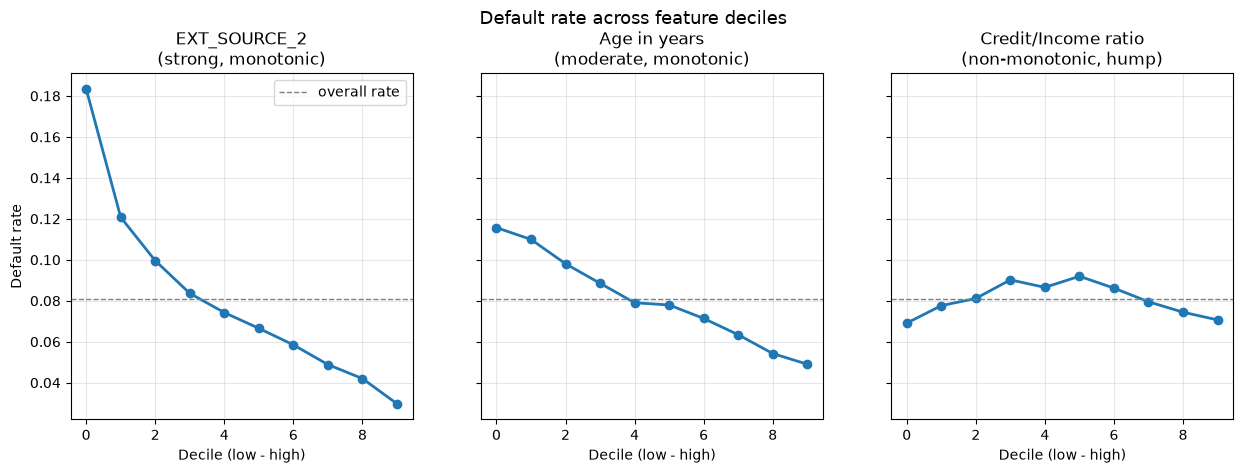

In [17]:
# Reusable decile-default-rate helper, so we don't repeat the block per feature.

def decile_default_rate(frame, feature, target="TARGET", q=10):
    valid = frame[[feature, target]].dropna()
    valid = valid.assign(decile=pd.qcut(valid[feature], q=q, labels=False, duplicates="drop"))
    return valid.groupby("decile")[target].mean()

features = ["EXT_SOURCE_2", "AGE_YEARS", "CREDIT_INCOME_RATIO"]
titles = ["EXT_SOURCE_2\n(strong, monotonic)",
          "Age in years\n(moderate, monotonic)",
          "Credit/Income ratio\n(non-monotonic, hump)"]

overall = df["TARGET"].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, feature, title in zip(axes, features, titles):
    rates = decile_default_rate(df,feature)
    ax.plot(rates.index, rates.values, marker="o", linewidth=2)
    ax.axhline(overall, color="grey", linestyle="--", linewidth=1, label="overall rate")
    ax.set_title(title)
    ax.set_xlabel("Decile (low - high)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Default rate")
axes[0].legend()
fig.suptitle("Default rate across feature deciles", fontsize=13, y=1.02)
plt.tight_layout
plt.show


**What I see:** Decile analysis of three candidate predictors reveals three distinct shapes. 'EXT_SOURCE_2 is strongly and cleanly monotonic: The default rates falls at every step from 18.4% (lowest decile) to 3.0% (highest), a ~6x spread. 'AGE_YEARS' is monotonic but weaker, declining from 11.6% (youngest) to 4.9% (oldest), a ~2.4x spread, with a plateau across the middle deciles. 'CREDIT_INCOME_RATIO' is non-monotonic: default rate rises to a peak of ~9.2% around the middle deciles, then falls at both the low and high extremes, producing a hump. 

**Interpretation:** The three features differ in both signal strenght and shape. The external score is the dominant predictor; age carries moderate signal; the credit-to-income ratio is the weakest and, critically, does not follow a simple monotonic trend. This non-monotonic hump is the concrete justification for Weight-of-Evidence binning: a linear model on the raw ration would force a single monotonic coefficient and misrepresent the relationship, whereas WoE assigns each bin its own weight and captures the hump faithfully. The three shapes therefore imply different binning strategies rather tha one uniform approach. 

**Decision:** In the scorecard (notebook 02), 'EXT_SOUCE_2' and 'AGE_YEARS' are candidates for monotonic (descending) binning, while 'CREDIT_INCOME_RATIO' requires unconstrained or peak-constrained binning to preserve its shape. The ratio's extreme upper taul (max ~84 driven by near-zero incomes) os a data=quality artifact inherited from the income outliers and will be capped during data preparation. 

## 6. Correlation and multicollinearity

Strongly correlated predictors destabilize logistic regression coefficients and undermine the interpretability that motivates the scorecard. This section examines correlations among the numeric features to flag redundant pairs for attention during feature selection. Multicollinearity primarily affects the scorecard (notebook 02), the tree-based challenger (notebook 03) is largely robust to it, as it selects one of a correlated pair at each split. 

In [18]:
# Correlation of numeric features with the target

numeric_cols = df.select_dtypes(include="number").columns 
target_corr = (
    df[numeric_cols].corr()["TARGET"]
    .drop("TARGET")
    .sort_values(key=abs, ascending=False)
)
print("Top 15 features by absolute correlation with TARGET:")
print(target_corr.head(15).round(4).to_string())

Top 15 features by absolute correlation with TARGET:
EXT_SOURCE_3                  -0.1789
EXT_SOURCE_2                  -0.1605
EXT_SOURCE_1                  -0.1553
AGE_YEARS                     -0.0782
DAYS_BIRTH                     0.0782
DAYS_EMPLOYED                  0.0750
REGION_RATING_CLIENT_W_CITY    0.0609
REGION_RATING_CLIENT           0.0589
DAYS_LAST_PHONE_CHANGE         0.0552
DAYS_ID_PUBLISH                0.0515
REG_CITY_NOT_WORK_CITY         0.0510
DAYS_EMPLOYED_ANOMALY         -0.0460
FLAG_EMP_PHONE                 0.0460
REG_CITY_NOT_LIVE_CITY         0.0444
FLAG_DOCUMENT_3                0.0443


In [19]:
# Find highly correlated features PAIRS (potential multicollinearity).

import numpy as np

corr_matrix = df[numeric_cols].drop(columns=["TARGET"]).corr().abs()

# Take the upper triangle only, to avoid duplicate pairs and self-correlations.

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Flag pairs above a threshold.

threshold = 0.8 
high_corr_pairs = (
    upper.stack()
    .loc[lambda s: s > threshold]
    .sort_values(ascending=False)
)
print(f"Feature pairs with |correlation| > {threshold}: {len(high_corr_pairs)}")
print(high_corr_pairs.round(3).to_string())

Feature pairs with |correlation| > 0.8: 113
DAYS_BIRTH                    AGE_YEARS                       1.000
FLAG_EMP_PHONE                DAYS_EMPLOYED_ANOMALY           1.000
YEARS_BUILD_AVG               YEARS_BUILD_MEDI                0.998
OBS_30_CNT_SOCIAL_CIRCLE      OBS_60_CNT_SOCIAL_CIRCLE        0.998
FLOORSMIN_AVG                 FLOORSMIN_MEDI                  0.997
FLOORSMAX_AVG                 FLOORSMAX_MEDI                  0.997
ENTRANCES_AVG                 ENTRANCES_MEDI                  0.997
ELEVATORS_AVG                 ELEVATORS_MEDI                  0.996
COMMONAREA_AVG                COMMONAREA_MEDI                 0.996
LIVINGAREA_AVG                LIVINGAREA_MEDI                 0.996
APARTMENTS_AVG                APARTMENTS_MEDI                 0.995
BASEMENTAREA_AVG              BASEMENTAREA_MEDI               0.994
LIVINGAPARTMENTS_AVG          LIVINGAPARTMENTS_MEDI           0.994
YEARS_BEGINEXPLUATATION_AVG   YEARS_BEGINEXPLUATATION_MEDI    0.994
LAND

**What I see:** 113 pairs above 0.8, the top offenders fall into recognizable groups: perfect correlations from engineered features(DAYS_BIRTH <> AGE_YEARS = 1.000, FLAG_EMP_PHONE <> DAYS_EMPLOYED_ANOMALY = 1.000), the housing _AVG/_MODE/_MEDI triplets (0.98-1.00), and the substantove AMT_CREDIT <> AMT_GOOD_PRICES = 0.987. Also worth noting from Cell 1: the strongest target correlations are the EXT_SOURCE_* scores, but only ~0.15-0.18 in absolute terms. 

**Interpretation:** Three distinct kinds of redundancy: engineered duplicates (same variable rescaled), structural duplicates (three summaries of one building measurement), and a genuine economic relationship confirm no single feature predicts default well, motivating thus a multi-feature model. And the model dependence: this multicollinearity destabilizes the logistic-regression scorecard but barely affects the tree challenger. 

**Decision:** Prune in feature selection (notebook 02): drop DAYS_BIRTH for AGE_YEARS, collapse each housing triplet to one variant, keep one of the AMT pair (or engineer a down-payment proxy from their difference). This stabilizes the scorecard coefficients. 

**Conclusions and Next steps** 

- Data Cleaning

Removing the AMT_INCOME_TOTAL 117M outlier, and reassess the extreme tail max.
Treating the XNA for CODE_GENDER
Converting the negative integer of DAYS_* positive encodings.


- Missingness handling

Missingness indicator flags for informative-missing features (like EXT_SOURCE_1) for the scorecard.
Implementing an imputation strategy for the logistic model, leave NaN as is for the LightGBM.


- Feature engineering

Formalization of the engineered ratios (CREDIT_INCOME_RATIO, and other candidates like the annuity-to-income, down payment proxy from the AMT_CREDIT / AMT_GOODS_PRICE).
Consideration of a log transform for income given its heavy right tail.


- Feature selection

Remove multicollinear redundancies, drop DAYS_BIRTH for AGE_YEARS, collapse housing triplets to one variant each, resolve AMT_CREDIT / AMT_GOODS_PRICE.


- Binning strategy (WoE)

Apply per feature binning: the monotonic for EXT_SOURCE_2 and age,  peak and unconstrained for the non monotonic credit to income ratio.


**All these points considered, Notebook 02 will implement these preparations and feature engineering steps, it will also be where the WoE will be developed.**